In [ ]:
import os

print(os.listdir())

['.config', 'Online Retail.xlsx', 'sample_data']


In [ ]:
import pandas as pd

df = pd.read_excel("Online Retail.xlsx")

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 541909
Columns: 8


In [ ]:
# Count missing values in each column
missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

Missing Values in Each Column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [ ]:
print("Column Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

First 5 Rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [ ]:
print(df.dtypes)

InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object


In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 5268


In [ ]:
# Show duplicate rows
duplicates = df[df.duplicated(keep=False)]

print("Rows involved in duplicates:", len(duplicates))

display(duplicates.head(10))

Rows involved in duplicates: 10147


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
548,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom


In [ ]:
# Create a working copy
df_clean = df.copy()

print("Original rows:", len(df))
print("Working copy rows:", len(df_clean))
print("Exact duplicate rows:", df_clean.duplicated().sum())

Original rows: 541909
Working copy rows: 541909
Exact duplicate rows: 5268


In [ ]:
# Count rows before removing duplicates
before = len(df_clean)

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates().copy()

# Count rows after removing duplicates
after = len(df_clean)

print("Rows before cleaning:", before)
print("Duplicate rows removed:", before - after)
print("Rows after cleaning:", after)
print("Remaining exact duplicates:", df_clean.duplicated().sum())

Rows before cleaning: 541909
Duplicate rows removed: 5268
Rows after cleaning: 536641
Remaining exact duplicates: 0


In [ ]:
# Count missing values after duplicate removal
missing_count = df_clean.isnull().sum()

# Calculate missing percentage
missing_percent = (missing_count / len(df_clean)) * 100

# Create a summary table
missing_summary = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percent.round(2)
})

display(missing_summary)

,Missing Count,Missing Percentage
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135037,25.16
Country,0,0.00


In [ ]:
print("Negative Quantity:", (df_clean["Quantity"] < 0).sum())
print("Zero Quantity:", (df_clean["Quantity"] == 0).sum())

print("Negative UnitPrice:", (df_clean["UnitPrice"] < 0).sum())
print("Zero UnitPrice:", (df_clean["UnitPrice"] == 0).sum())

Negative Quantity: 10587
Zero Quantity: 0
Negative UnitPrice: 2
Zero UnitPrice: 2510


In [ ]:
# Display records with negative UnitPrice
negative_price = df_clean[df_clean["UnitPrice"] < 0]

display(negative_price)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [ ]:
zero_price = df_clean[df_clean["UnitPrice"] == 0]

print("Zero-price records:", len(zero_price))

display(zero_price.head(10))


Zero-price records: 2510


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom


In [ ]:
zero_price = df_clean[df_clean["UnitPrice"] == 0]

print("Total zero-price records:", len(zero_price))

print(
    "Missing Description:",
    zero_price["Description"].isna().sum()
)

print(
    "Negative Quantity:",
    (zero_price["Quantity"] < 0).sum()
)

print(
    "Missing CustomerID:",
    zero_price["CustomerID"].isna().sum()
)

Total zero-price records: 2510
Missing Description: 1454
Negative Quantity: 1336
Missing CustomerID: 2470


In [ ]:
# Check invoice numbers beginning with C (commonly cancellations)
cancelled = df_clean[
    df_clean["InvoiceNo"].astype(str).str.startswith("C")
]

print("Cancellation invoice records:", len(cancelled))
print("Negative quantity in these records:",
      (cancelled["Quantity"] < 0).sum())
print("Positive quantity in these records:",
      (cancelled["Quantity"] > 0).sum())

Cancellation invoice records: 9251
Negative quantity in these records: 9251
Positive quantity in these records: 0


In [ ]:
# Calculate transaction value
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["UnitPrice"]

print("Revenue column created successfully!")
display(df_clean[[
    "InvoiceNo", "Quantity", "UnitPrice", "Revenue"
]].head(10))

Revenue column created successfully!


,InvoiceNo,Quantity,UnitPrice,Revenue
0,536365,6,2.55,15.30
1,536365,6,3.39,20.34
2,536365,8,2.75,22.00
3,536365,6,3.39,20.34
4,536365,6,3.39,20.34
5,536365,2,7.65,15.30
6,536365,6,4.25,25.50
7,536366,6,1.85,11.10
8,536366,6,1.85,11.10
9,536367,32,1.69,54.08


In [ ]:
print("Total records:", len(df_clean))

print("Positive revenue records:",
      (df_clean["Revenue"] > 0).sum())

print("Negative revenue records:",
      (df_clean["Revenue"] < 0).sum())

print("Zero revenue records:",
      (df_clean["Revenue"] == 0).sum())

print("Total Revenue (preliminary):",
      round(df_clean["Revenue"].sum(), 2))

Total records: 536641
Positive revenue records: 524878
Negative revenue records: 9253
Zero revenue records: 2510
Total Revenue (preliminary): 9726006.95


In [ ]:
# Save cleaned dataset as a CSV file
df_clean.to_csv("online_retail_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Rows:", len(df_clean))
print("Columns:", len(df_clean.columns))

Cleaned dataset saved successfully!
Rows: 536641
Columns: 9


In [ ]:
from google.colab import files
files.download("online_retail_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Verify the saved cleaned dataset
df_check = pd.read_csv("online_retail_cleaned.csv")

print("Rows:", df_check.shape[0])
print("Columns:", df_check.shape[1])

print("\nColumn names:")
print(df_check.columns.tolist())

print("\nFirst 5 rows:")
display(df_check.head())

print("\nMissing values:")
print(df_check.isnull().sum())

Rows: 536641
Columns: 9

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Revenue']

First 5 rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34



Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
Revenue             0
dtype: int64


In [ ]:
# Convert InvoiceDate to datetime
df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"])

# Create Year-Month column
df_clean["YearMonth"] = df_clean["InvoiceDate"].dt.to_period("M").astype(str)

# Calculate monthly revenue
monthly_sales = (
    df_clean.groupby("YearMonth")["Revenue"]
    .sum()
    .reset_index()
)

# Display monthly sales
display(monthly_sales)

# Find the month with highest revenue
highest_month = monthly_sales.loc[monthly_sales["Revenue"].idxmax()]

print("Month with highest revenue:", highest_month["YearMonth"])
print("Revenue:", round(highest_month["Revenue"], 2))

,YearMonth,Revenue
0,2010-12,746723.610
1,2011-01,558448.560
2,2011-02,497026.410
3,2011-03,682013.980
4,2011-04,492367.841
5,2011-05,722094.100
6,2011-06,689977.230
7,2011-07,680156.991
8,2011-08,681386.460
9,2011-09,1017596.682


Month with highest revenue: 2011-11
Revenue: 1456145.8


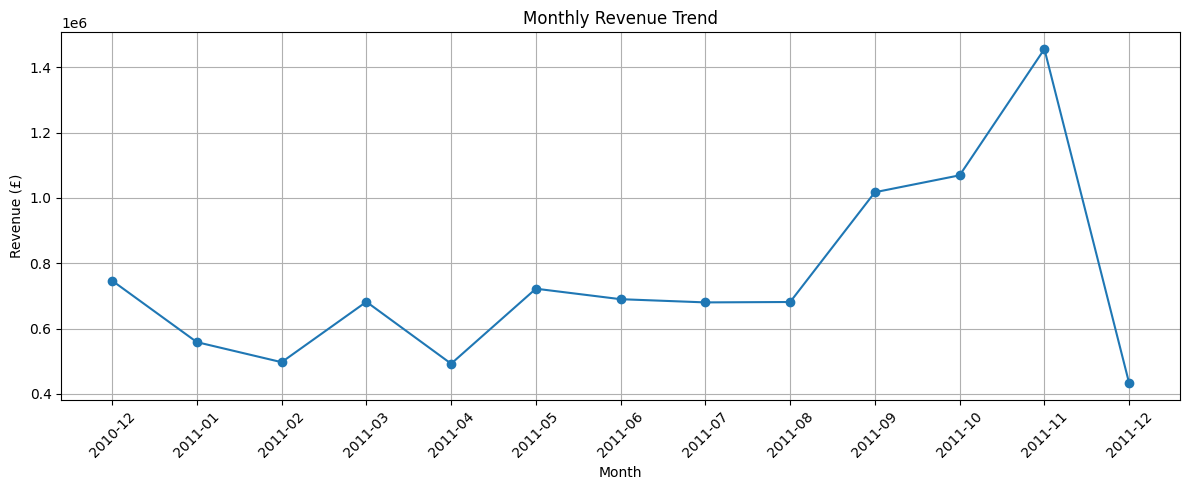

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales["YearMonth"],
    monthly_sales["Revenue"],
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()


In [ ]:
# Country-wise revenue analysis
country_sales = (
    df_clean.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

print("Top 10 countries by revenue:")
display(country_sales.head(10))


Top 10 countries by revenue:


,Country,Revenue
0,United Kingdom,8167128.184
1,Netherlands,284661.540
2,EIRE,262993.380
3,Germany,221509.470
4,France,197317.110
5,Australia,137009.770
6,Switzerland,56363.050
7,Spain,54756.030
8,Belgium,40910.960
9,Sweden,36585.410


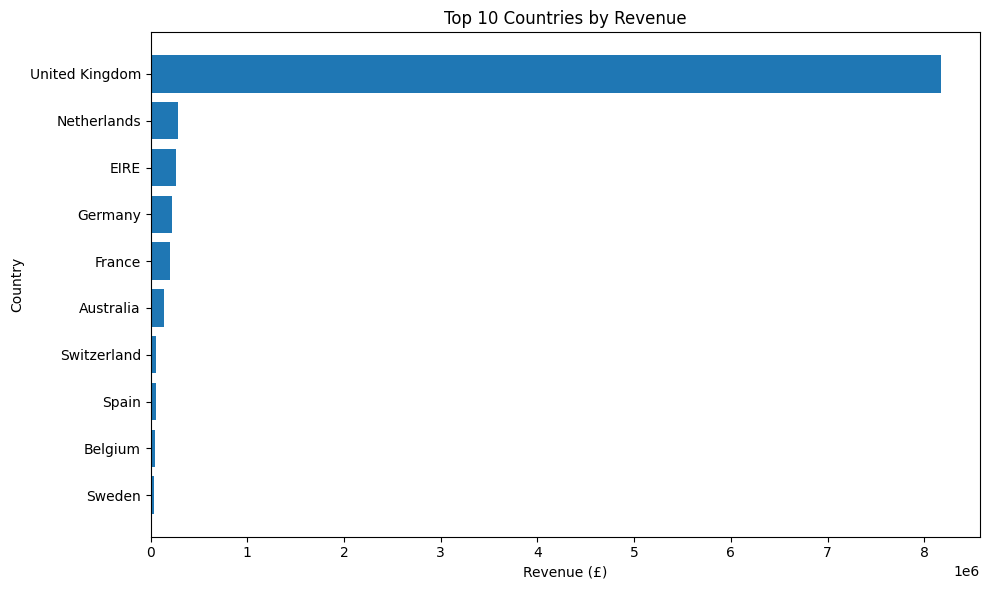

In [ ]:
import matplotlib.pyplot as plt

top10_countries = country_sales.head(10).sort_values(
    "Revenue", ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top10_countries["Country"],
    top10_countries["Revenue"]
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()

plt.show()

In [ ]:
# Top 10 products by revenue
product_sales = (
    df_clean.dropna(subset=["Description"])
    .groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

print("Top 10 Products by Revenue:")
display(product_sales.head(10))

Top 10 Products by Revenue:


,Description,Revenue
0,DOTCOM POSTAGE,206245.48
1,REGENCY CAKESTAND 3 TIER,164459.49
2,WHITE HANGING HEART T-LIGHT HOLDER,99612.42
3,PARTY BUNTING,98243.88
4,JUMBO BAG RED RETROSPOT,92175.79
5,RABBIT NIGHT LIGHT,66661.63
6,POSTAGE,66230.64
7,PAPER CHAIN KIT 50'S CHRISTMAS,63715.24
8,ASSORTED COLOUR BIRD ORNAMENT,58792.42
9,CHILLI LIGHTS,53746.66


In [ ]:
display(product_sales.head(10))

,Description,Revenue
0,DOTCOM POSTAGE,206245.48
1,REGENCY CAKESTAND 3 TIER,164459.49
2,WHITE HANGING HEART T-LIGHT HOLDER,99612.42
3,PARTY BUNTING,98243.88
4,JUMBO BAG RED RETROSPOT,92175.79
5,RABBIT NIGHT LIGHT,66661.63
6,POSTAGE,66230.64
7,PAPER CHAIN KIT 50'S CHRISTMAS,63715.24
8,ASSORTED COLOUR BIRD ORNAMENT,58792.42
9,CHILLI LIGHTS,53746.66


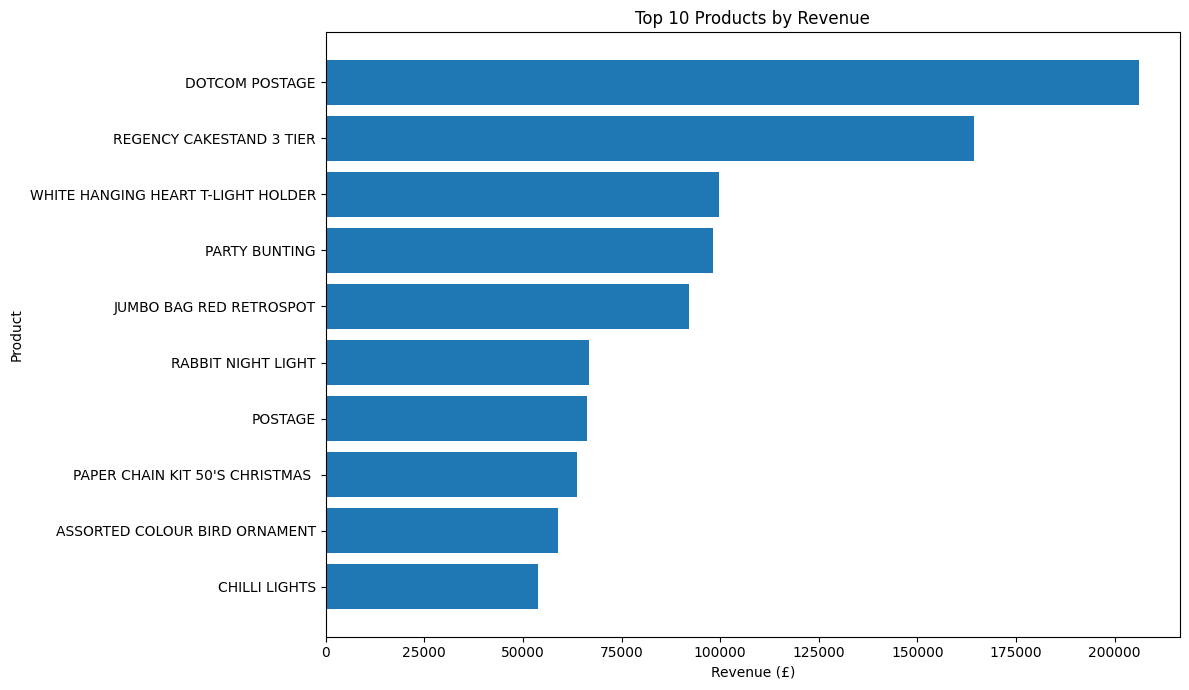

In [ ]:
import matplotlib.pyplot as plt

top10_products = product_sales.head(10).sort_values(
    "Revenue", ascending=True
)

plt.figure(figsize=(12, 7))

plt.barh(
    top10_products["Description"],
    top10_products["Revenue"]
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")
plt.tight_layout()

plt.show()

In [ ]:
# Remove rows where CustomerID is missing for customer analysis
customer_data = df_clean.dropna(subset=["CustomerID"]).copy()

# Calculate revenue by customer
customer_sales = (
    customer_data.groupby("CustomerID")
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Total_Orders=("InvoiceNo", "nunique")
    )
    .sort_values("Total_Revenue", ascending=False)
    .reset_index()
)

print("Top 10 Customers by Revenue:")
display(customer_sales.head(10))

Top 10 Customers by Revenue:


,CustomerID,Total_Revenue,Total_Orders
0,14646.0,279489.02,77
1,18102.0,256438.49,62
2,17450.0,187322.17,55
3,14911.0,132458.73,248
4,12415.0,123725.45,26
5,14156.0,113214.59,66
6,17511.0,88125.38,46
7,16684.0,65892.08,31
8,13694.0,62690.54,60
9,15311.0,59284.19,118


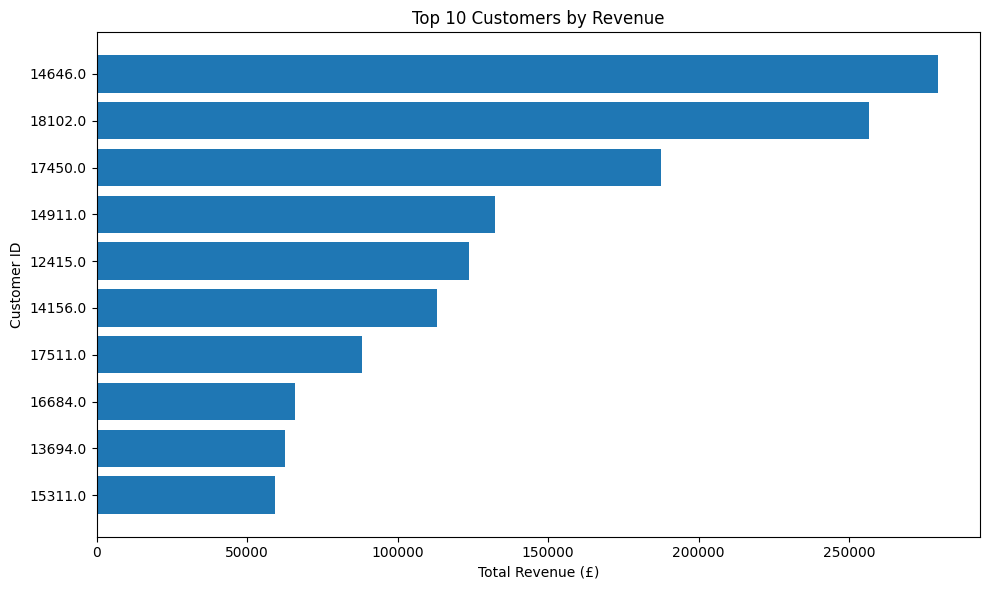

In [ ]:
import matplotlib.pyplot as plt

top10_customers = customer_sales.head(10).sort_values(
    "Total_Revenue", ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top10_customers["CustomerID"].astype(str),
    top10_customers["Total_Revenue"]
)

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Total Revenue (£)")
plt.ylabel("Customer ID")
plt.tight_layout()

plt.show()

In [ ]:
# Summary of completed analysis

print("===== E-COMMERCE ANALYTICS SUMMARY =====")

print("Total cleaned records:", len(df_clean))
print("Total countries:", df_clean["Country"].nunique())
print("Unique products:", df_clean["StockCode"].nunique())
print("Customers with CustomerID:",
      df_clean["CustomerID"].nunique())

print("Preliminary total revenue: £",
      round(df_clean["Revenue"].sum(), 2))

print("\nHighest revenue month:")
display(highest_month)

print("\nTop 5 countries:")
display(country_sales.head(5))

print("\nTop 5 products:")
display(product_sales.head(5))

print("\nTop 5 customers:")
display(customer_sales.head(5))

===== E-COMMERCE ANALYTICS SUMMARY =====
Total cleaned records: 536641
Total countries: 38
Unique products: 4070
Customers with CustomerID: 4372
Preliminary total revenue: £ 9726006.95

Highest revenue month:


,11
YearMonth,2011-11
Revenue,1456145.8



Top 5 countries:


,Country,Revenue
0,United Kingdom,8167128.184
1,Netherlands,284661.540
2,EIRE,262993.380
3,Germany,221509.470
4,France,197317.110



Top 5 products:


,Description,Revenue
0,DOTCOM POSTAGE,206245.48
1,REGENCY CAKESTAND 3 TIER,164459.49
2,WHITE HANGING HEART T-LIGHT HOLDER,99612.42
3,PARTY BUNTING,98243.88
4,JUMBO BAG RED RETROSPOT,92175.79



Top 5 customers:


,CustomerID,Total_Revenue,Total_Orders
0,14646.0,279489.02,77
1,18102.0,256438.49,62
2,17450.0,187322.17,55
3,14911.0,132458.73,248
4,12415.0,123725.45,26
